# Tracking Observable Exploration

Compact diagnostics for the row-wise GNSS tracking observable dataset. The notebook now keeps only dataset-level checks and one selected-track drilldown.

In [49]:
from pathlib import Path
import json

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update(
    {
        "font.size": 12,
        "axes.titlesize": 15,
        "axes.labelsize": 12,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "legend.fontsize": 9,
        "legend.title_fontsize": 10,
        "lines.linewidth": 1.5,
        "figure.dpi": 120,
    }
)

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
output_dir = project_root / "outputs" / "tracking_exploration"
output_dir.mkdir(parents=True, exist_ok=True)

DATASET_HANDLE = "rodrigodlf/backpropagation/versions/13"
SPEED_OF_LIGHT_MPS = 299_792_458.0
GPS_CARRIER_FREQUENCY_HZ = {"L1": 1_575.42e6, "L5": 1_176.45e6}
GPS_CARRIER_WAVELENGTH_M = {
    name: SPEED_OF_LIGHT_MPS / frequency_hz
    for name, frequency_hz in GPS_CARRIER_FREQUENCY_HZ.items()
}

## Dataset Layout

In [50]:
dataset_path = Path(kagglehub.dataset_download(DATASET_HANDLE))
observables_dir = dataset_path / "observables"

meta = json.loads((observables_dir / "meta.json").read_text())
partitions = pd.DataFrame(meta["partitions"])
partitions["path"] = partitions["path"].astype(str)
partitions["file_size_mb"] = partitions["path"].map(
    lambda name: (observables_dir / name).stat().st_size / 1024**2
)
partitions = partitions.sort_values("city").reset_index(drop=True)

diagnostics = pd.read_csv(observables_dir / meta["diagnostics"])

diagnostics_overview = (
    diagnostics.assign(
        acq_success=diagnostics["acq_success"].astype(bool),
        loss_of_lock=diagnostics["loss_of_lock"].astype(bool),
    )
    .groupby(["frequency", "severity"], observed=True)
    .agg(
        cases=("tracking_case_id", "size"),
        acq_successes=("acq_success", "sum"),
        loss_of_lock_cases=("loss_of_lock", "sum"),
        acq_metric_mean=("acq_metric", "mean"),
        acq_metric_min=("acq_metric", "min"),
        acq_metric_max=("acq_metric", "max"),
    )
)

print(f"Dataset path: {dataset_path}")
print(f"Observable partitions: {len(partitions)}")
print(f"Total rows from meta: {partitions['rows'].sum():,}")
print(f"Diagnostics rows: {len(diagnostics):,}")
print(f"Peaceful period removed: {meta.get('peaceful_period_sec')} s")

display(partitions)
display(diagnostics_overview)

Dataset path: /home/rodrigo/.cache/kagglehub/datasets/rodrigodlf/backpropagation/versions/13
Observable partitions: 4
Total rows from meta: 1,435,500
Diagnostics rows: 33
Peaceful period removed: 30.0 s


,city,path,rows,file_size_mb
0,palmas,observables_palmas.csv,391500,77.044868
1,porto_alegre,observables_porto_alegre.csv,348000,70.417056
2,presidente_prudente,observables_presidente_prudente.csv,348000,72.828314
3,sao_jose_dos_campos,observables_sao_jose_dos_campos.csv,348000,72.757339


cases  acq_successes  loss_of_lock_cases  acq_metric_mean  \
frequency severity                                                              
L1        strong       16             16                  13              NaN   
          weak         17             17                   0              NaN   

                    acq_metric_min  acq_metric_max  
frequency severity                                  
L1        strong               NaN             NaN  
          weak                 NaN             NaN

## Load Observables

In [51]:
observable_dtypes = {
    "epoch_idx": "int32",
    "time_sec": "float32",
    "city": "category",
    "svid": "category",
    "frequency": "category",
    "pseudorange_est_m": "float64",
    "carrier_phase_est_m": "float64",
    "los_pseudorange_m": "float64",
    "los_phase_m": "float64",
    "elevation_deg": "float32",
    "scint_delay_m": "float32",
    "scint_phase_m": "float32",
    "tracked_intensity": "float32",
    "true_intensity": "float32",
    "severity": "category",
}

frames = [
    pd.read_csv(observables_dir / row.path, dtype=observable_dtypes)
    for row in partitions.itertuples(index=False)
]
observables = pd.concat(frames, ignore_index=True)
del frames

positive = np.finfo("float32").tiny
observables["pseudorange_residual_m"] = observables["pseudorange_est_m"] - observables["los_pseudorange_m"]
observables["tracked_scint_phase_m"] = observables["carrier_phase_est_m"] - observables["los_phase_m"]
observables["carrier_wavelength_m"] = observables["frequency"].astype(str).map(GPS_CARRIER_WAVELENGTH_M).astype("float64")
observables["phase_error_raw_m"] = observables["tracked_scint_phase_m"] - observables["scint_phase_m"]
observables["phase_error_wrapped_m"] = (
    (observables["phase_error_raw_m"] + 0.5 * observables["carrier_wavelength_m"])
    % observables["carrier_wavelength_m"]
    - 0.5 * observables["carrier_wavelength_m"]
)
observables["phase_error_wrapped_cycles"] = observables["phase_error_wrapped_m"] / observables["carrier_wavelength_m"]
observables["intensity_ratio_db"] = 10.0 * np.log10(
    np.clip(observables["tracked_intensity"].to_numpy(), positive, None)
    / np.clip(observables["true_intensity"].to_numpy(), positive, None)
)

print("observables shape:", observables.shape)
print("memory usage [MB]:", observables.memory_usage(deep=True).sum() / 1024**2)
observables.head()

observables shape: (1435500, 22)
memory usage [MB]: 313.16938304901123


,epoch_idx,time_sec,city,svid,frequency,pseudorange_est_m,carrier_phase_est_m,los_pseudorange_m,los_phase_m,elevation_deg,...,tracked_intensity,true_intensity,severity,pseudorange_residual_m,tracked_scint_phase_m,carrier_wavelength_m,phase_error_raw_m,phase_error_wrapped_m,phase_error_wrapped_cycles,intensity_ratio_db
0,1500,30.000000,palmas,G01,L1,2.197876e+07,-2.197876e+07,2.197876e+07,-2.197876e+07,40.376472,...,0.994928,1.095340,strong,-3.725290e-09,-0.001673,0.190294,-0.001673,-0.001673,-0.008790,-0.417572
1,1501,30.020000,palmas,G01,L1,2.197875e+07,-2.197875e+07,2.197875e+07,-2.197875e+07,40.376621,...,0.995161,1.114090,strong,1.551621e-04,-0.002103,0.190294,-0.001947,-0.001947,-0.010234,-0.490266
2,1502,30.040001,palmas,G01,L1,2.197874e+07,-2.197874e+07,2.197874e+07,-2.197874e+07,40.376770,...,1.044052,1.129407,strong,4.029162e-04,-0.002575,0.190294,-0.002172,-0.002172,-0.011412,-0.341285
3,1503,30.059999,palmas,G01,L1,2.197873e+07,-2.197873e+07,2.197873e+07,-2.197873e+07,40.376919,...,1.044295,1.143934,strong,6.416701e-04,-0.001610,0.190294,-0.000968,-0.000968,-0.005087,-0.395777
4,1504,30.080000,palmas,G01,L1,2.197872e+07,-2.197872e+07,2.197872e+07,-2.197872e+07,40.377068,...,1.170691,1.163598,strong,8.942336e-04,-0.005150,0.190294,-0.004255,-0.004255,-0.022362,0.026393


## Overview Diagnostics

In [52]:
track_keys = ["city", "svid", "frequency", "severity"]

missing_summary = (
    observables.isna().mean()
    .mul(100)
    .rename("missing_percent")
    .to_frame()
    .query("missing_percent > 0")
    .sort_values("missing_percent", ascending=False)
)

track_summary = (
    observables.groupby(track_keys, observed=True)
    .agg(
        rows=("time_sec", "size"),
        time_min_sec=("time_sec", "min"),
        time_max_sec=("time_sec", "max"),
        elevation_min_deg=("elevation_deg", "min"),
        elevation_max_deg=("elevation_deg", "max"),
        scint_delay_std_m=("scint_delay_m", "std"),
        true_intensity_mean=("true_intensity", "mean"),
        tracked_intensity_mean=("tracked_intensity", "mean"),
        intensity_ratio_db_median=("intensity_ratio_db", "median"),
        phase_wrapped_rmse_m=("phase_error_wrapped_m", lambda x: np.sqrt(np.nanmean(np.square(x)))),
        pseudorange_residual_median_m=("pseudorange_residual_m", "median"),
    )
    .reset_index()
)
expected_rows_per_track = int(track_summary["rows"].mode().iloc[0])
track_summary["complete_length"] = track_summary["rows"].eq(expected_rows_per_track)

overview = (
    observables.groupby(["frequency", "severity"], observed=True)
    .agg(
        rows=("time_sec", "size"),
        tracks=("svid", "nunique"),
        elevation_min_deg=("elevation_deg", "min"),
        elevation_median_deg=("elevation_deg", "median"),
        scint_delay_std_m=("scint_delay_m", "std"),
        true_intensity_mean=("true_intensity", "mean"),
        tracked_intensity_mean=("tracked_intensity", "mean"),
        intensity_ratio_db_median=("intensity_ratio_db", "median"),
        phase_wrapped_rmse_m=("phase_error_wrapped_m", lambda x: np.sqrt(np.nanmean(np.square(x)))),
        pseudorange_residual_std_m=("pseudorange_residual_m", "std"),
    )
)

print(f"Tracks: {len(track_summary):,}")
print(f"Expected rows per complete track: {expected_rows_per_track:,}")
print(f"Complete-length tracks: {track_summary['complete_length'].sum():,}")

display(overview)
display(missing_summary if not missing_summary.empty else pd.DataFrame({"missing_percent": []}))
display(track_summary.sort_values(["city", "frequency", "severity", "svid"]).head(20))

Tracks: 33
Expected rows per complete track: 43,500
Complete-length tracks: 33


rows  tracks  elevation_min_deg  elevation_median_deg  \
frequency severity                                                            
L1        strong    696000       8          18.441496             34.306320   
          weak      739500       9          16.797174             39.344368   

                    scint_delay_std_m  true_intensity_mean  \
frequency severity                                           
L1        strong             1.655546             1.000297   
          weak               0.540357             1.000373   

                    tracked_intensity_mean  intensity_ratio_db_median  \
frequency severity                                                      
L1        strong                  1.004807                  -0.016049   
          weak                    1.000312                  -0.007135   

                    phase_wrapped_rmse_m  pseudorange_residual_std_m  
frequency severity                                                    
L1        strong                0.006043                    1.655546  
          weak                  0.003557                    0.540357

,missing_percent


,city,svid,frequency,severity,rows,time_min_sec,time_max_sec,elevation_min_deg,elevation_max_deg,scint_delay_std_m,true_intensity_mean,tracked_intensity_mean,intensity_ratio_db_median,phase_wrapped_rmse_m,pseudorange_residual_median_m,complete_length
0,palmas,G01,L1,strong,43500,30.0,899.97998,40.376472,46.951603,0.755342,1.001817,1.002651,-0.014347,0.005730,1.095667,True
1,palmas,G03,L1,strong,43500,30.0,899.97998,18.441496,20.674194,0.390225,0.986210,0.979232,-0.041830,0.005073,0.006771,True
2,palmas,G08,L1,strong,43500,30.0,899.97998,34.545818,38.592842,0.870828,1.008094,1.011388,-0.014867,0.005937,0.252183,True
4,palmas,G14,L1,strong,43500,30.0,899.97998,18.448555,23.644018,0.474239,0.986810,1.033844,0.039174,0.005203,0.889284,True
3,palmas,G11,L1,weak,43500,30.0,899.97998,55.612934,59.636765,0.311400,0.999394,0.998638,-0.010529,0.003569,-0.211906,True
5,palmas,G22,L1,weak,43500,30.0,899.97998,30.100060,32.552715,0.122763,1.000913,1.000362,-0.009875,0.003559,0.153863,True
6,palmas,G23,L1,weak,43500,30.0,899.97998,34.735474,37.057068,0.374031,0.999744,0.999980,-0.008197,0.003560,0.148965,True
7,palmas,G27,L1,weak,43500,30.0,899.97998,18.726948,23.509197,0.096645,1.000581,1.002080,-0.002338,0.003523,0.124525,True
8,palmas,G31,L1,weak,43500,30.0,899.97998,39.672596,42.930084,0.775142,1.000278,0.999172,-0.009367,0.003609,-0.981128,True
12,porto_alegre,G11,L1,strong,43500,30.0,899.97998,61.792313,63.749905,2.035129,0.996666,1.004377,-0.000512,0.006120,2.698079,True


## Selected Track

In [53]:
EXAMPLE_NUMBER = 12  # 1-based index over the available complete tracks.

example_tracks = track_summary[track_summary["complete_length"]].copy()
if example_tracks.empty:
    example_tracks = track_summary.copy()

example_tracks = example_tracks.sort_values(
    ["city", "frequency", "severity", "svid"],
    kind="mergesort",
).reset_index(drop=True)
example_tracks.insert(0, "example_number", np.arange(1, len(example_tracks) + 1))

if not 1 <= EXAMPLE_NUMBER <= len(example_tracks):
    raise ValueError(f"EXAMPLE_NUMBER must be between 1 and {len(example_tracks)}.")

selected = example_tracks.iloc[EXAMPLE_NUMBER - 1]
selected_key = {key: selected[key] for key in track_keys}

mask = np.ones(len(observables), dtype=bool)
for key, value in selected_key.items():
    mask &= observables[key].astype(str).to_numpy() == str(value)
track = observables.loc[mask].sort_values("epoch_idx").copy()

track["pseudorange_residual_centered_m"] = track["pseudorange_residual_m"] - track["pseudorange_residual_m"].median()
track["phase_error_centered_m"] = track["phase_error_raw_m"] - track["phase_error_raw_m"].median()

selected_track_stats = pd.Series(
    {
        "example_number": EXAMPLE_NUMBER,
        "n_examples": len(example_tracks),
        "rows": len(track),
        "time_min_sec": float(track["time_sec"].min()),
        "time_max_sec": float(track["time_sec"].max()),
        "elevation_min_deg": float(track["elevation_deg"].min()),
        "elevation_max_deg": float(track["elevation_deg"].max()),
        "true_intensity_mean": float(track["true_intensity"].mean()),
        "tracked_intensity_mean": float(track["tracked_intensity"].mean()),
        "intensity_ratio_db_median": float(track["intensity_ratio_db"].median()),
        "phase_wrapped_rmse_m": float(np.sqrt(np.nanmean(track["phase_error_wrapped_m"] ** 2))),
        "phase_centered_rmse_m": float(np.sqrt(np.nanmean(track["phase_error_centered_m"] ** 2))),
        "pseudorange_residual_std_m": float(track["pseudorange_residual_m"].std()),
    },
    name="selected_track_stats",
)

print(f"Selected example {EXAMPLE_NUMBER} of {len(example_tracks)}")
print(selected_key)
display(selected_track_stats.to_frame())
display(example_tracks.head(20))
track.head()

Selected example 12 of 33
{'city': 'porto_alegre', 'svid': 'G23', 'frequency': 'L1', 'severity': 'strong'}


,selected_track_stats
example_number,12.000000
n_examples,33.000000
rows,43500.000000
time_min_sec,30.000000
time_max_sec,899.979980
elevation_min_deg,28.964588
elevation_max_deg,34.066826
true_intensity_mean,0.994392
tracked_intensity_mean,0.998552
intensity_ratio_db_median,-0.007680


,example_number,city,svid,frequency,severity,rows,time_min_sec,time_max_sec,elevation_min_deg,elevation_max_deg,scint_delay_std_m,true_intensity_mean,tracked_intensity_mean,intensity_ratio_db_median,phase_wrapped_rmse_m,pseudorange_residual_median_m,complete_length
0,1,palmas,G01,L1,strong,43500,30.0,899.97998,40.376472,46.951603,0.755342,1.001817,1.002651,-0.014347,0.005730,1.095667,True
1,2,palmas,G03,L1,strong,43500,30.0,899.97998,18.441496,20.674194,0.390225,0.986210,0.979232,-0.041830,0.005073,0.006771,True
2,3,palmas,G08,L1,strong,43500,30.0,899.97998,34.545818,38.592842,0.870828,1.008094,1.011388,-0.014867,0.005937,0.252183,True
3,4,palmas,G14,L1,strong,43500,30.0,899.97998,18.448555,23.644018,0.474239,0.986810,1.033844,0.039174,0.005203,0.889284,True
4,5,palmas,G11,L1,weak,43500,30.0,899.97998,55.612934,59.636765,0.311400,0.999394,0.998638,-0.010529,0.003569,-0.211906,True
5,6,palmas,G22,L1,weak,43500,30.0,899.97998,30.100060,32.552715,0.122763,1.000913,1.000362,-0.009875,0.003559,0.153863,True
6,7,palmas,G23,L1,weak,43500,30.0,899.97998,34.735474,37.057068,0.374031,0.999744,0.999980,-0.008197,0.003560,0.148965,True
7,8,palmas,G27,L1,weak,43500,30.0,899.97998,18.726948,23.509197,0.096645,1.000581,1.002080,-0.002338,0.003523,0.124525,True
8,9,palmas,G31,L1,weak,43500,30.0,899.97998,39.672596,42.930084,0.775142,1.000278,0.999172,-0.009367,0.003609,-0.981128,True
9,10,porto_alegre,G11,L1,strong,43500,30.0,899.97998,61.792313,63.749905,2.035129,0.996666,1.004377,-0.000512,0.006120,2.698079,True


,epoch_idx,time_sec,city,svid,frequency,pseudorange_est_m,carrier_phase_est_m,los_pseudorange_m,los_phase_m,elevation_deg,...,severity,pseudorange_residual_m,tracked_scint_phase_m,carrier_wavelength_m,phase_error_raw_m,phase_error_wrapped_m,phase_error_wrapped_cycles,intensity_ratio_db,pseudorange_residual_centered_m,phase_error_centered_m
652500,1500,30.000000,porto_alegre,G23,L1,2.263273e+07,-2.263273e+07,2.263273e+07,-2.263273e+07,28.964588,...,strong,0.000000,-0.000328,0.190294,-0.000328,-0.000328,-0.001726,0.202431,0.257124,3234.517402
652501,1501,30.020000,porto_alegre,G23,L1,2.263272e+07,-2.263272e+07,2.263272e+07,-2.263272e+07,28.964706,...,strong,0.000039,0.001812,0.190294,0.001851,0.001851,0.009726,0.180130,0.257163,3234.519581
652502,1502,30.040001,porto_alegre,G23,L1,2.263271e+07,-2.263271e+07,2.263271e+07,-2.263271e+07,28.964827,...,strong,0.000094,0.002810,0.190294,0.002904,0.002904,0.015262,-0.102539,0.257218,3234.520634
652503,1503,30.059999,porto_alegre,G23,L1,2.263270e+07,-2.263270e+07,2.263270e+07,-2.263270e+07,28.964945,...,strong,0.000120,0.001132,0.190294,0.001251,0.001251,0.006576,-0.126697,0.257243,3234.518981
652504,1504,30.080000,porto_alegre,G23,L1,2.263269e+07,-2.263269e+07,2.263269e+07,-2.263269e+07,28.965065,...,strong,0.000180,0.002452,0.190294,0.002632,0.002632,0.013833,0.212824,0.257304,3234.520362


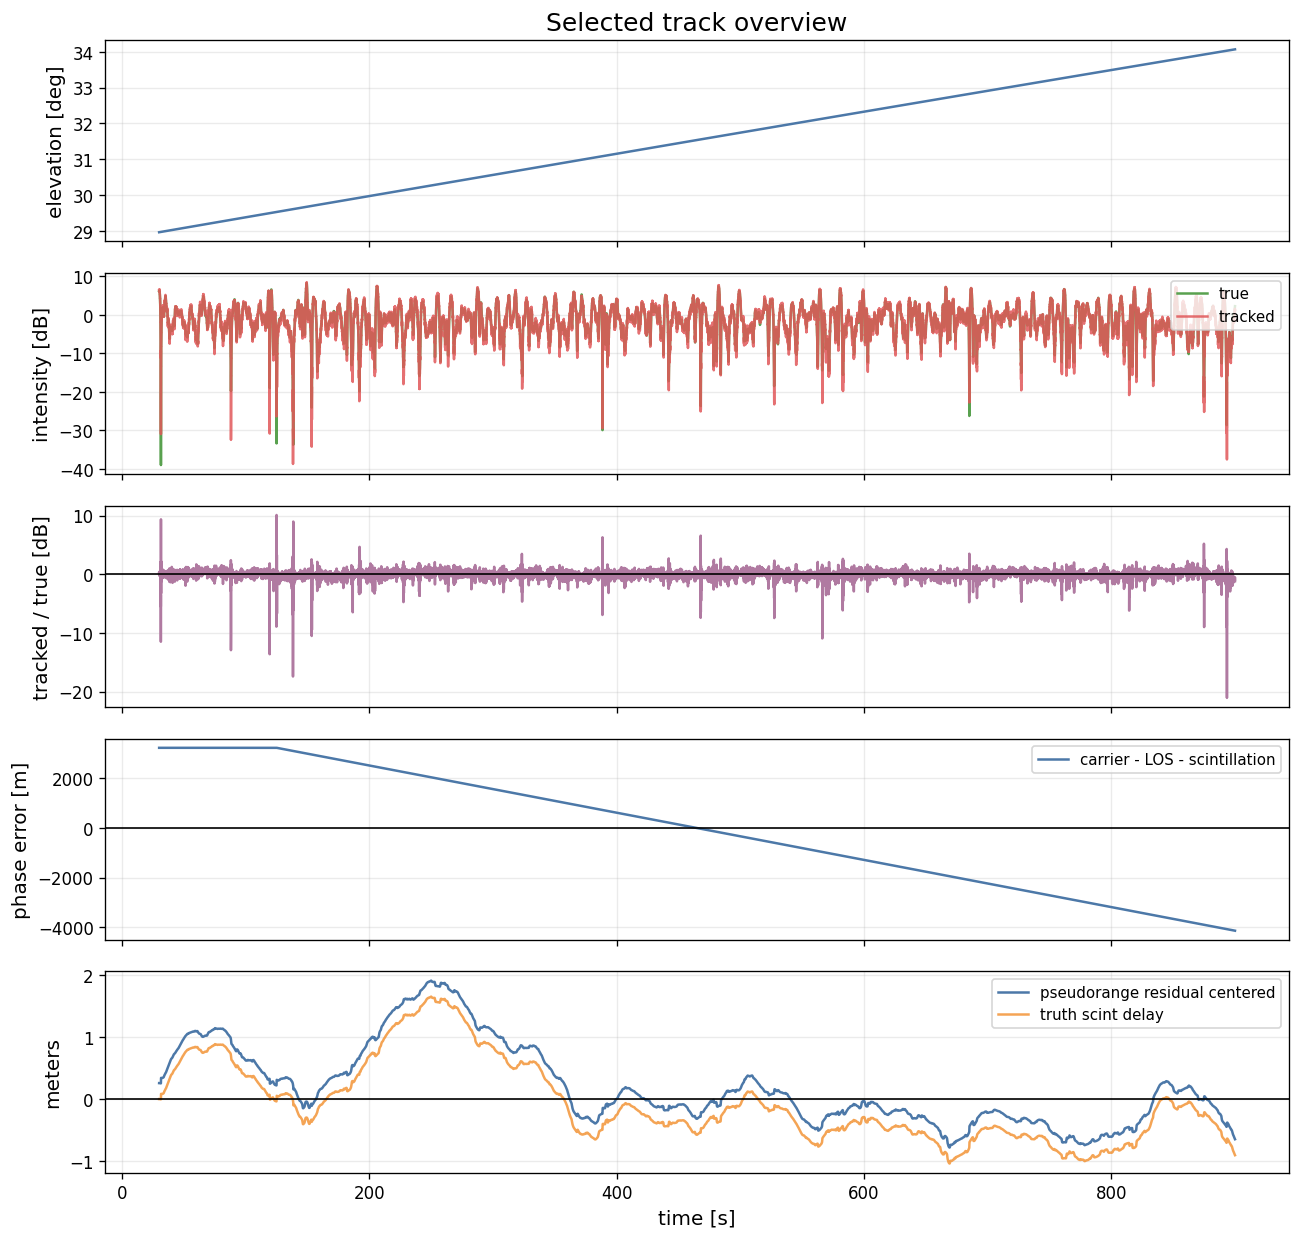

In [54]:
fig, axes = plt.subplots(5, 1, figsize=(11, 10.5), sharex=True)
t = track["time_sec"].to_numpy()

axes[0].plot(t, track["elevation_deg"], color="#4c78a8")
axes[0].set_ylabel("elevation [deg]")
axes[0].set_title("Selected track overview")
axes[0].grid(alpha=0.25)

axes[1].plot(t, 10.0 * np.log10(np.clip(track["true_intensity"], positive, None)), label="true", color="#59a14f")
axes[1].plot(t, 10.0 * np.log10(np.clip(track["tracked_intensity"], positive, None)), label="tracked", color="#e15759", alpha=0.85)
axes[1].set_ylabel("intensity [dB]")
axes[1].legend(loc="upper right")
axes[1].grid(alpha=0.25)

axes[2].plot(t, track["intensity_ratio_db"].clip(-30, 30), color="#b07aa1")
axes[2].axhline(0.0, color="black", linewidth=1)
axes[2].set_ylabel("tracked / true [dB]")
axes[2].grid(alpha=0.25)

axes[3].plot(t, track["phase_error_centered_m"], label="carrier - LOS - scintillation", color="#4c78a8")
axes[3].axhline(0.0, color="black", linewidth=1)
axes[3].set_ylabel("phase error [m]")
axes[3].legend(loc="upper right")
axes[3].grid(alpha=0.25)

axes[4].plot(t, track["pseudorange_residual_centered_m"], label="pseudorange residual centered", color="#4c78a8")
axes[4].plot(t, track["scint_delay_m"], label="truth scint delay", color="#f28e2b", alpha=0.8)
axes[4].axhline(0.0, color="black", linewidth=1)
axes[4].set_xlabel("time [s]")
axes[4].set_ylabel("meters")
axes[4].legend(loc="upper right")
axes[4].grid(alpha=0.25)

fig.tight_layout()
fig.savefig(output_dir / "v7_selected_track_overview.png", bbox_inches="tight")
plt.show()

## Outputs

This notebook writes only `outputs/tracking_exploration/v7_selected_track_overview.png`. Tables are displayed in-memory because the source CSVs are the canonical dataset product.